# Multimodal Movie Recap: YouTube Film → Summary Story → Peak Points → Recap Under 10 Minutes

**AI11 · Module 8 · Multimodal AI Systems: Speech, Text, and Conversational Agents · Assignment 1**
**Student:** Karthikeyan K  ·  **Faculty:** Dr. J. B. Simha

**Problem statement.** A full-length film takes more than an hour to watch. The task is to build a multimodal
AI system that takes a YouTube movie, processes its video, audio and text, writes a summary story, finds the
important (peak) moments with their timestamps, cuts those moments out of the film and joins them into a recap
shorter than ten minutes. The summary is evaluated with BLEU.

**Assignment objectives**
1. Implement a multimodal pipeline that processes video, audio and text.
2. Apply speech-to-text and summarisation to produce a concise summary story.
3. Identify peak points and map them to time indices in the original film.
4. Extract the relevant segments (OpenCV) and combine them into a recap of less than ten minutes.

**Workflow**

`YouTube Video → Movie → Audio + Video → Transcript → Summary Story → Peak Points → Time Index → Video Segment Extraction → Movie Recap → BLEU Evaluation`

**Input film.** *Detour* (1945, dir. Edgar G. Ulmer), a public-domain film noir of 67 minutes with heavy
first-person voice-over narration. Public-domain status allows the recap clips to be shared freely, and a
human-written Wikipedia plot summary serves as the BLEU reference.

**How to read this notebook.** Each component follows the same sequence: *Objective → Purpose → Methodology →
Prompt (only where an instruction-following AI model is called) → Implementation → Coding → Output → Inference →
Insights → Summary*. The full pipeline lives in the `recap/` package (`python run_pipeline.py`). The slowest stages
(22 min of transcription, about 33 min of LLM summarisation on a CPU) cache their results as JSON; this notebook loads those
results, re-runs the lighter components live, and repeats one live LLM call per prompt so each prompt can be seen in action.

**Where prompts appear.** Only the summarisation component (Section 6) uses a model that follows written
instructions (Qwen2.5-7B-Instruct). It has three prompts (notes, editor, repair), each shown directly before the call it controls. Whisper, the emotion classifier and the sentence-embedding model take raw audio
or text with no instructions, and the remaining components are algorithmic, so they have no Prompt step.

## 1. Environment and reproducibility

### Objective
Prepare a reproducible environment: fixed random seeds, recorded library versions and one shared configuration.

### Purpose
Every later component reads the same paths and parameters; without a fixed environment the reported numbers could not be reproduced.

### Methodology
The project root is added to the import path, `config.yaml` is loaded through the same helper the pipeline uses, seeds are fixed for Python and NumPy, and the versions of the key libraries are collected into a table.

### Implementation
The cell below imports the shared libraries, sets the seed (42), loads the configuration and defines plotting colours. A second cell lists the library versions used for the reported results.

In [1]:
# Imports, seeds, configuration and plotting style shared by every section
import json, random, sys, time, warnings
from pathlib import Path

import cv2
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from recap.utils import load_config, load_json, fmt_ts

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

cfg = load_config(ROOT / "config.yaml")
OUT = Path(cfg["output_dir"])
VIDEO = cfg["input"]["local_path"]
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"

### Output
Library versions used for every result in this notebook:

In [2]:
import faster_whisper, sentence_transformers, transformers, nltk, sacrebleu
versions = {"python": sys.version.split()[0], "opencv": cv2.__version__, "librosa": librosa.__version__,
            "faster-whisper": faster_whisper.__version__, "transformers": transformers.__version__,
            "sentence-transformers": sentence_transformers.__version__, "nltk": nltk.__version__,
            "sacrebleu": sacrebleu.__version__, "numpy": np.__version__}
pd.DataFrame([versions]).T.rename(columns={0: "version"})

19:04:33 | INFO | TensorFlow version 2.20.0 available.


,version
python,3.10.0
opencv,4.11.0
librosa,0.11.0
faster-whisper,1.2.1
transformers,5.8.1
sentence-transformers,5.4.0
nltk,3.9.4
sacrebleu,2.6.0
numpy,2.2.6


### Inference
The environment loads without errors and the versions above are the ones behind the reported results.

### Insights
Every model in the pipeline is pre-trained and used zero-shot, so there is no training step. Reproducibility therefore depends on fixed model versions, temperature 0 for the LLM and a fixed seed for the random baseline.

### Summary
With a fixed environment in place, the pipeline can start from its input: the YouTube film.

## 2. Input: YouTube video → movie file

### Objective
Obtain the film from YouTube and confirm that the video stream is complete and readable.

### Purpose
Every later stage (audio, transcript, features, clip extraction) depends on a valid, correctly-tracked source file.

### Methodology
`recap/ingest.py` downloads the film with **yt-dlp** at ≤480p and explicitly selects the **original English audio track** (this upload also carries auto-dubbed Russian, Korean and Portuguese tracks). **OpenCV** reads the stream properties (frame rate, frame count, resolution) and samples frames evenly across the running time.

### Implementation
`probe_video()` opens the file with `cv2.VideoCapture` and returns its properties. The loop then seeks to six evenly spaced positions (10%–95% of the film) and reads one frame at each.

In [3]:
# Probe the film with OpenCV and sample six evenly spaced frames
from recap.ingest import probe_video

info = probe_video(VIDEO)
cap = cv2.VideoCapture(VIDEO)
sample_times = np.linspace(0.1, 0.95, 6) * info["duration_seconds"]
sample_frames = []
for t in sample_times:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(t * info["fps"]))  # seek by frame index
    ok, frame = cap.read()
    sample_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
cap.release()

### Output
Stream properties and the six sampled frames:

,fps,frame_count,width,height,duration_seconds
0,29.97,121627,640,480,4058.29


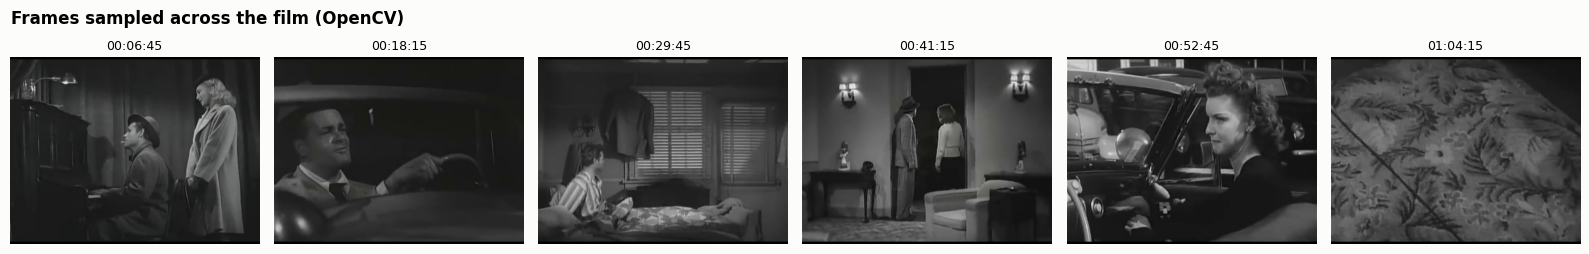

In [4]:
display(pd.DataFrame([{k: (round(v, 2) if isinstance(v, float) else v) for k, v in info.items() if k != "path"}]))
fig, axes = plt.subplots(1, 6, figsize=(16, 2.6))
for ax, t, frame in zip(axes, sample_times, sample_frames):
    ax.imshow(frame)
    ax.set_title(fmt_ts(t), fontsize=9)
    ax.axis("off")
fig.suptitle("Frames sampled across the film (OpenCV)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the chart**

* **Observation:** Six frames from 00:00 to the final minutes show the black-and-white picture, steady framing and mostly interior or night scenes.
* **Interpretation:** Colour carries no information in this film; brightness, motion and cuts are the only usable visual cues.
* **Key insight:** The visual features in Section 5 are therefore built on grey-level motion and histogram cuts, not on colour.

### Inference
The film is 640×480 at 30 fps and runs for 67 min 38 s; the sampled frames are black and white and evenly cover the story from the opening to the ending.

### Insights
Choosing the audio track is a real multimodal pitfall: a blind default could have fed a machine-dubbed voice to speech recognition. Because the footage is black and white, hue and saturation carry almost no information, so the visual features later rely on brightness and motion.

### Summary
A valid video file is in place; the next component separates its soundtrack from the picture.

## 3. Audio extraction: movie → audio + video

### Objective
Separate the soundtrack from the picture in a format suitable for speech recognition and audio analysis.

### Purpose
Speech-to-text and the audio features operate on the soundtrack alone, while OpenCV keeps working on the video stream.

### Methodology
**ffmpeg** (bundled with `imageio-ffmpeg`, so no system install is needed) demuxes the soundtrack to a 16 kHz mono WAV, the format Whisper expects, plus an MP3 copy. A log-mel spectrogram, $S_{dB} = 10\log_{10}(\text{Mel}(|STFT(y)|^2))$, visualises the speech energy of a short excerpt.

### Implementation
`librosa.load` reads the extracted WAV. The full waveform is downsampled only for plotting, and a 20-second dialogue excerpt at 08:03 is converted to a 64-band log-mel spectrogram.

In [5]:
# Load the extracted soundtrack and compute a log-mel spectrogram of one dialogue excerpt
wav_path = OUT / "audio" / "audio_16k_mono.wav"
y, sr = librosa.load(wav_path, sr=16000)
excerpt_start = 8 * 60 + 3  # a dialogue scene at 08:03
excerpt = y[excerpt_start * sr:(excerpt_start + 20) * sr]
mel_db = librosa.power_to_db(librosa.feature.melspectrogram(y=excerpt, sr=sr, n_mels=64), ref=np.max)

### Output
The results of the code above are displayed below.

Soundtrack: 67.6 min at 16000 Hz, peak amplitude 0.89


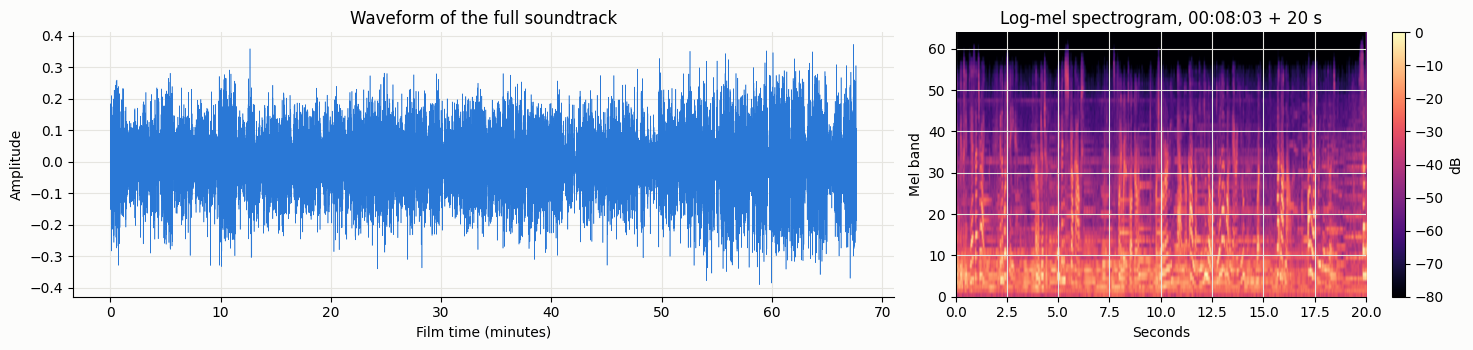

In [6]:
print(f"Soundtrack: {len(y) / sr / 60:.1f} min at {sr} Hz, peak amplitude {np.abs(y).max():.2f}")
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
step = 400  # downsample for plotting only
axes[0].plot(np.arange(0, len(y), step) / sr / 60, y[::step], color=BLUE, lw=0.4)
axes[0].set(title="Waveform of the full soundtrack", xlabel="Film time (minutes)", ylabel="Amplitude")
img = axes[1].imshow(mel_db, origin="lower", aspect="auto", cmap="magma", extent=[0, 20, 0, 64])
axes[1].set(title=f"Log-mel spectrogram, {fmt_ts(excerpt_start)} + 20 s", xlabel="Seconds", ylabel="Mel band")
fig.colorbar(img, ax=axes[1], label="dB")
plt.tight_layout()
plt.show()

**Reading the chart**

* **Observation:** The waveform stays well below full scale for the whole film with short louder bursts; the spectrogram of the 08:03 excerpt shows stacked harmonic bands separated by gaps.
* **Interpretation:** Harmonic bands with gaps are the signature of voiced speech and pauses between lines; the louder bursts are music cues and raised voices.
* **Key insight:** The soundtrack is clean enough for speech recognition, and loudness bursts are a usable arousal signal for peaks.

### Inference
The waveform peaks below half of full scale, and the spectrogram shows stacked harmonic bands of voices separated by short pauses, so the soundtrack carries clean, recognisable speech.

### Insights
A 16 kHz mono signal keeps the band up to 8 kHz where most speech energy lies while cutting the data about six-fold compared with 48 kHz stereo. The 1945 soundtrack is quiet: clean text-to-speech narration was far louder and at first masked the film dialogue in the recap, so the renderer now matches narration loudness to the film's speech level.

### Summary
The speech track is ready for transcription, the first text-producing component.

## 4. Speech-to-text: transcript with a time index

### Objective
Convert the soundtrack into text while recording when every line and word was spoken.

### Purpose
These timestamps are the *time index* that links summary sentences, peak points and video segments throughout the pipeline.

### Methodology
`faster-whisper` runs OpenAI's **Whisper `small.en`** (244 M parameters, encoder–decoder transformer) through CTranslate2 with int8 weights on the CPU, with voice-activity filtering and word-level timestamps. `condition_on_previous_text=False` prevents the repetition loops Whisper can fall into on long audio. Decoding confidence per segment is $\exp(\overline{\log p})$, the exponent of the average token log-probability. Whisper takes audio only and is not given instructions, so this component has no prompt.

### Implementation
The full-film transcription took 22 minutes and is cached in `transcript.json`; the cell loads it and derives word counts, speech coverage and per-segment confidence.

In [7]:
# Load the cached Whisper transcript and compute summary statistics
tr = load_json(OUT / "transcript.json")
segs = tr["segments"]
words = sum(len(s["text"].split()) for s in segs)
conf = np.exp([s["avg_logprob"] for s in segs])
speech_time = sum(s["end"] - s["start"] for s in segs)

### Output
Transcript statistics, eight sample lines with their time index, word-level timestamps and the confidence distribution:

,segments,words,speech minutes,share of film with speech,ASR runtime (min),median confidence
0,946,8418,39.3,58%,21.8,0.843


,start,end,text
0,00:06:15,00:06:19,"But how we felt about each other, well, there was nothing very unusual in that."
1,00:06:19,00:06:22,"I was an ordinary healthy guy and she was an ordinary healthy girl,"
2,00:06:22,00:06:25,"When you add those two together, you get an ordinary, healthy romance,"
3,00:06:26,00:06:27,which is the old story.
4,00:06:28,00:06:28,Sure.
5,00:06:29,00:06:32,"But somehow, the most wonderful thing in the world."
6,00:06:33,00:06:42,"Well, I was a pretty lucky guy."
7,00:06:55,00:06:57,"Mr. Padarovsky, I presume."


Word-level timestamps for one line: [('Sure.', 388.44)]


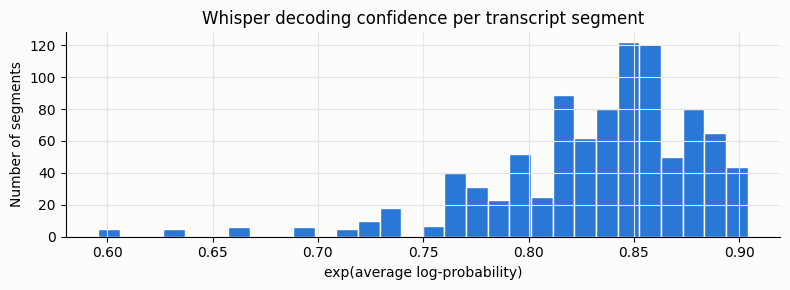

In [8]:
display(pd.DataFrame([{"segments": len(segs), "words": words, "speech minutes": round(speech_time / 60, 1),
                       "share of film with speech": f"{speech_time / tr['info']['audio_duration']:.0%}",
                       "ASR runtime (min)": round(tr["info"]["processing_seconds"] / 60, 1),
                       "median confidence": round(float(np.median(conf)), 3)}]))
display(pd.DataFrame([{"start": fmt_ts(s["start"]), "end": fmt_ts(s["end"]), "text": s["text"]} for s in segs[60:68]]))
print("Word-level timestamps for one line:", [(w["word"].strip(), w["start"]) for w in segs[64]["words"]])
plt.figure(figsize=(8, 3))
plt.hist(conf, bins=30, color=BLUE, edgecolor="white")
plt.title("Whisper decoding confidence per transcript segment")
plt.xlabel("exp(average log-probability)")
plt.ylabel("Number of segments")
plt.tight_layout()
plt.show()

**Reading the chart**

* **Observation:** Most segments sit at high decoding confidence, with a thin tail of low-confidence lines.
* **Interpretation:** The tail is mainly music, overlapping speech and one-word exclamations, not whole misheard scenes.
* **Key insight:** Transcript errors are local; summarisation over 5-minute chunks is robust to the occasional wrong line.

### Inference
The transcript contains 946 segments covering a little under half of the running time, and the confidence histogram is concentrated at the high end with a thin tail of uncertain lines.

### Insights
Speech filling under half of a feature film is normal (music, silent action and pauses fill the rest). Low-confidence lines are mostly music, overlapping speech or short exclamations. At about 3× faster than real time on a CPU, transcription is the second most expensive stage, which is why it is cached.

### Summary
The timestamped transcript is the text modality used by summarisation and by peak detection.

## 5. Multimodal signals: audio, video and text emotion

### Objective
Measure how intense each moment of the film is in each modality.

### Purpose
Peak points should not be chosen from text alone: the dramatic moment in a scene is often marked by a raised voice, fast editing or emotional wording.

### Methodology
* **Audio (librosa):** RMS loudness, onset strength (spectral flux) and amplitude fluctuation within each second (the session heuristic: calm speech has steady peak amplitude, agitated speech does not), combined as arousal $= 0.4\,\hat{L}_{dB} + 0.3\,\hat{O} + 0.3\,\hat{\sigma}_{RMS}$ (hats = min-max scaled).
* **Video (OpenCV):** one pass at 2 frames per second; a shot cut is declared when the Bhattacharyya distance between consecutive HSV histograms exceeds 0.35; motion is the mean absolute grey-level difference; activity $= 0.6\,\widehat{\log(1+m)} + 0.4\,\widehat{\text{cut density}}$.
* **Text (transformers):** a DistilRoBERTa emotion classifier labels each transcript line; intensity $= 1 - P(\text{neutral})$.

The modalities are computed independently and fused later (post-fusion). None of these models takes instructions, so there is no prompt.

### Implementation
The three feature files were produced by `recap/features.py` during the pipeline run. The cell loads them and derives shot statistics and the distribution of emotion labels.

In [9]:
# Load the cached per-modality features and summarise each one
fa, fv, fe = (load_json(OUT / f) for f in ("features_audio.json", "features_visual.json", "features_text_emotion.json"))
shots = np.array(fv["shot_boundaries"])
emotion_counts = pd.Series([e["label"] for e in fe]).value_counts()

### Output
The results of the code above are displayed below.

Shot cuts detected: 312  |  median shot length: 8.0 s
Audio arousal: mean 0.51, 95th percentile 0.71
Visual activity: mean 0.34, 95th percentile 0.55


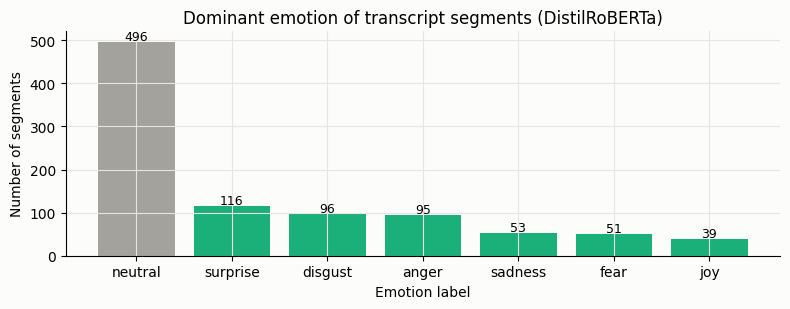

In [10]:
print(f"Shot cuts detected: {len(shots)}  |  median shot length: {np.median(np.diff(shots)):.1f} s")
print(f"Audio arousal: mean {np.mean(fa['arousal']):.2f}, 95th percentile {np.percentile(fa['arousal'], 95):.2f}")
print(f"Visual activity: mean {np.mean(fv['activity']):.2f}, 95th percentile {np.percentile(fv['activity'], 95):.2f}")
plt.figure(figsize=(8, 3.2))
plt.bar(emotion_counts.index, emotion_counts.values, color=[GREY if l == "neutral" else AQUA for l in emotion_counts.index])
for i, v in enumerate(emotion_counts.values):
    plt.text(i, v + 5, str(v), ha="center", fontsize=9)
plt.title("Dominant emotion of transcript segments (DistilRoBERTa)")
plt.xlabel("Emotion label")
plt.ylabel("Number of segments")
plt.tight_layout()
plt.show()

**Reading the chart**

* **Observation:** Neutral is the largest class; among the non-neutral labels surprise, disgust and anger lead and joy is rare.
* **Interpretation:** A tense film noir produces many suspicious and hostile exchanges, so non-neutral lines cluster around the conflicts.
* **Key insight:** Emotion intensity (1 - P(neutral)) separates dramatic lines from routine dialogue and earns its 15 % fusion weight.

### Inference
About half of the lines are neutral; surprise, disgust and anger are the most common non-neutral emotions and joy is rare. 312 shot cuts were detected.

### Insights
The emotional profile fits a film noir: tense, suspicious and hostile exchanges dominate, so non-neutral lines are a useful marker of dramatic moments. The visual features are low-level (motion, cuts); scenes that are important but visually calm depend on the other modalities.

### Summary
The three per-moment intensity signals are ready to be fused when the peak points are chosen (Section 7).

## 6. Text processing and summarisation: the summary story

### Objective
Turn about 9,000 words of transcript into a short summary story that a viewer can follow from start to end, with the right people doing the right things and the climax and ending included.

### Purpose
The summary story decides what the recap tells: every story sentence later becomes one peak point, one clip and one narrated chapter card. An error here (a wrong character, a missing ending) is carried into the final video.

### Methodology
The transcript is split into 13 chunks of about 5 minutes. A local LLM, **Qwen2.5-7B-Instruct** served by Ollama at temperature 0 (deterministic decoding, seed 42), processes them in order with the story written so far as context (*rolling context*). Version 2 of the summariser adds four grounding steps on top of the rolling context used in run E:

1. **Grounded notes (LLM call per chunk).** The model first lists 2–4 events as *who – does what – to whom (quote)*, with a short quote from the excerpt as evidence, and only then writes exactly 2 story sentences from those notes (3 for the final chunk, which holds the climax and the ending); if it stops after the notes, a short fallback call writes them.
2. **Editor pass (one LLM call).** The whole draft is checked against the notes of every chunk: role errors are corrected, repeated events removed, and missing key events (deaths, arrests, the ending) restored.
3. **Key-event check (deterministic) with a targeted addition (LLM call only when needed).** Transcript lines with strong evidence of a death, killing or murder are located per chunk (at least two such lines, negations such as "didn't kill" ignored). If the story says nothing about them for that chunk, one call writes the missing sentence from the quoted lines.
4. **Character-entry check (deterministic) with a targeted repair (LLM call only when needed).** For each cast member the time $t_c$ at which the name is first spoken is found in the transcript. A sentence from a chunk ending at $t_e$ may not name character $c$ if $t_c > t_e$; offending sentences are rewritten by one repair call and re-checked.

A near-duplicate filter (cosine similarity ≥ 0.88) and a TextRank extractive summary of the same length (baseline) are kept from version 1. Each sentence keeps the time span of its chunk, the first and coarse level of the time index.

### Prompt
**Prompt 1 of 4: grounded notes and story** (`NOTES_PROMPT` in `recap/summarize.py`), sent once per chunk. The values in
braces are filled in by the code cell below.

```text
You are writing a plot summary of the film "{title}" from its speech transcript.
There are no speaker labels. Much of the film is first-person voice-over narration by the main
character, so "I" in the narration usually means him.

Cast list from the credits, for spelling and roles only: {cast}
Name a character only if that name is spoken in this excerpt or already appears in the story so far;
otherwise describe the person ("a waitress", "a man"). Characters enter the film at different times.

Story so far (earlier parts of the film):
{context}

Transcript excerpt for the NEXT part of the film ({start} to {end}):
"""{text}"""

Work in two steps.

NOTES: list the 2 to 4 most important events of this part, one per line, in the form
"who - does what - to whom (quote)", where the quote is a few words from the excerpt that prove it.
Check who performs each action before writing it. A character telling a story about the past is not
doing it now, and a person who is only mentioned in someone's story is not present.
Deaths, crimes, arrests, threats and decisions that change the plot matter most.

STORY: then write {n} plain sentences of 15 to 25 words each, based only on your NOTES.
Be concrete: say who does what, where, and with what result. Avoid vague phrases such as
"grapples with his feelings" or "struggles with his past". Third person, present tense.
Do not repeat the story so far. No headings or lists.

NOTES:
```

**Filled-in values for this call:** `title` = "Detour (1945)"; `cast` = the cast list in `config.yaml`; `context` = the last
six draft sentences written before chunk 4; `start`–`end` = the time span of chunk 4; `n` = "2"; `text` = the transcript
of chunk 4. Decoding: temperature 0, seed 42, at most 520 new tokens. Chunk 4 is shown because it is the part of the film in
which the earlier run E wrongly placed Vera in the car.

**Fallback in the same call path** (`STORY_PROMPT`): if the model stops after the notes and writes no story, one short
call turns that chunk's notes into the sentences (at most 160 new tokens).

```text
You are writing a plot summary of the film "{title}".
Event notes for the part of the film from {start} to {end}, each written as "who - does what - to whom (quote)":
{notes}

Write {n} plain sentences of 15 to 25 words each that tell these events as a story, in time order.
Be concrete: who does what, where, and with what result. Use only these notes.
Third person, present tense. No headings or lists.

Sentences:
```

### Implementation
The summary was produced by the pipeline (`summary.json`, all 13 chunks plus the editor and repair calls) and is loaded from cache. The three cells below then repeat **one live call for each prompt** with exactly the prompts shown, so each prompt can be seen controlling the model: (1) the notes call for chunk 4, (2) the editor pass over the full draft, (3) the key-event check followed by an addition call for the climax that run E left out, and (4) the character-entry check followed by a repair call on the run-E sentence that broke the rule. Every live call needs Ollama with `qwen2.5:7b`; if it is unreachable, the cell falls back to the cached pipeline output and says so.

In [11]:
# Coding, call 1 of 4: grounded NOTES -> STORY for chunk 4 with the prompt shown above
import requests
from recap.summarize import (KEY_EVENT_PROMPT, KEY_STORY, NOTES_PROMPT, STORY_PROMPT, REVISE_PROMPT, REPAIR_PROMPT, _clean, cast_characters,
                             entry_violations, first_mentions, key_lines, ollama_available, ollama_generate, parse_notes_story, parse_revision,
                             split_sentences)


def llm(prompt, max_tokens, ctx=4096):
    # One live call; returns (text, source) and never raises, so the notebook runs end to end without Ollama
    if not LIVE:
        return None, "Ollama not reachable: cached pipeline output shown"
    t = time.time()
    try:
        return ollama_generate(prompt, cfg["summary"], max_tokens, num_ctx=ctx), f"live call ({time.time() - t:.0f} s)"
    except requests.RequestException as exc:
        return None, f"live call failed ({exc.__class__.__name__}): cached pipeline output shown"


summ = load_json(OUT / "summary.json")
LIVE = ollama_available(cfg["summary"])
draft = summ.get("draft_sentences", summ["story_sentences"])
draft_chunks = summ.get("draft_chunks", summ["sentence_chunks"])
k = 3                                                         # chunk 4 (zero-based index 3)
chunk = summ["chunks"][k]
previous = [s for s, c in zip(draft, draft_chunks) if c < k][-6:]   # same context window as the pipeline
prompt_notes = NOTES_PROMPT.format(title=cfg["input"]["title"], cast=cfg["input"]["cast"],
                                   context=" ".join(previous) or "(this is the beginning of the film)",
                                   start=fmt_ts(chunk["start"]), end=fmt_ts(chunk["end"]), n="2", text=chunk["text"])
raw, src_notes = llm(prompt_notes, 520)
live_notes, live_story = parse_notes_story(raw) if raw else (chunk.get("notes", []), chunk.get("summary", ""))
if raw and not live_story and live_notes:
    # Same fallback as the pipeline: write the story from the notes
    raw_story, _ = llm(STORY_PROMPT.format(title=cfg["input"]["title"], start=fmt_ts(chunk["start"]), end=fmt_ts(chunk["end"]),
                                           n="2", notes="\n".join(f"- {x}" for x in live_notes)), 160)
    live_story = _clean(raw_story or "")

### Prompt
**Prompt 2 of 4: editor pass** (`REVISE_PROMPT` in `recap/summarize.py`), sent once for the whole film. `draft` = every draft
sentence tagged with its chunk number; `notes` = the event notes of every chunk; `words` = the draft length in words. Decoding: temperature 0, at most 900 new
tokens, 8,192-token context.

```text
You are the editor of a plot summary of the film "{title}".
Cast list from the credits, for spelling and roles only: {cast}

Draft story. Each line starts with the [part] of the film it comes from:
{draft}

Event notes written from the transcript of each part:
{notes}

Revise the draft into a clean story:
- Keep the time order and keep the [part] tag at the start of every line.
- If a sentence disagrees with the notes of its part (for example the wrong person doing an action), correct it.
- If two sentences tell the same event, keep only the better one.
- If an important event in the notes is missing (a death, a crime, an arrest, how the film ends), add one sentence for it with that part's tag.
- If a sentence is vague, replace it with the concrete events from the notes of its part.
- Keep the details: do not shorten sentences. The revised story should be about {words} words long, like the draft.
- Use only facts from the notes. 15 to 25 words per sentence, third person, present tense.
Output one sentence per line in the form "[part] sentence" and nothing else.

Revised story:
```

In [12]:
# Coding, call 2 of 4: editor pass over the full draft with the prompt shown above
draft_text = "\n".join(f"[{c + 1}] {s}" for s, c in zip(draft, draft_chunks))
notes_text = "\n".join(f"[{c['index'] + 1}] " + "; ".join(c.get("notes", [])) for c in summ["chunks"])
prompt_rev = REVISE_PROMPT.format(title=cfg["input"]["title"], cast=cfg["input"]["cast"], draft=draft_text, notes=notes_text,
                                  words=sum(len(s.split()) for s in draft))
raw_rev, src_rev = llm(prompt_rev, 900, ctx=8192)
live_revised = parse_revision(raw_rev or summ.get("revision_raw", ""), len(summ["chunks"]), max(6, len(draft) // 2))

### Prompt
**Prompt 3 of 4: key-event addition** (`KEY_EVENT_PROMPT` in `recap/summarize.py`), sent only for a chunk whose transcript
has strong evidence of a death, killing or murder that the story does not mention. `story` = the story sentences of that
chunk; `lines` = the evidence lines with their timestamps. Decoding: temperature 0, at most 90 new tokens.

```text
You are completing a plot summary of the film "{title}".
Cast list from the credits, for spelling and roles only: {cast}

Story sentences already written for this part of the film ({start} to {end}):
{story}

These transcript lines from the same part show an important event (a death, a killing, a crime or
the police) that the story does not mention yet. There are no speaker labels; the main character
narrates in the first person, so "I" in narration means him.
{lines}

Write ONE sentence of 15 to 25 words that states this event plainly: who does what to whom and the
result. Rules:
- Use only what these lines and the story support. Do not add places, motives or emotions they do not state.
- Keep the nature of the event exactly as the lines give it: if they say it happened by accident or
  "without meaning to", say so.
- An accusation is not a confession: if one person accuses another, write it as an accusation.
- The narrator is Al Roberts. Write about him as "Al": never use "I", "me" or "my". Use character names.
- Do not quote the lines; describe what happens in your own words. Speech recognition may mishear a
  name (for example "Bill" for "Vera"); use the story and the cast list to tell who is meant.
Third person, present tense. Output only the sentence.

Sentence:
```

In [13]:
# Coding, call 3 of 4: key-event check on run E and on the final story, then a live addition for the climax chunk
run_e = load_json(OUT.parent / "experiments" / "summary_qwen2.5-7b.json")


def key_event_gaps(story):
    # Chunks with strong death/killing evidence in the dialogue but no matching story sentence
    gaps = []
    for c in story["chunks"]:
        lines = key_lines(c, segs)
        told = [s for s, k in zip(story["story_sentences"], story["sentence_chunks"]) if k == c["index"]]
        if lines and not any(KEY_STORY.search(t) for t in told):
            gaps.append({"chunk": c["index"] + 1, "span": f"{fmt_ts(c['start'])}-{fmt_ts(c['end'])}",
                         "evidence": " | ".join(lines[:3]), "story says": " ".join(told)})
    return gaps


gaps_e, gaps_final = key_event_gaps(run_e), key_event_gaps(summ)
c = summ["chunks"][-1]                                     # the climax and ending of the film
told = [s for s, k in zip(run_e["story_sentences"], run_e["sentence_chunks"]) if k == c["index"]]
prompt_key = KEY_EVENT_PROMPT.format(title=cfg["input"]["title"], cast=cfg["input"]["cast"], start=fmt_ts(c["start"]),
                                     end=fmt_ts(c["end"]), story=" ".join(told) or "(none)", lines="\n".join(key_lines(c, segs)))
raw_key, src_key = llm(prompt_key, 90)
added_live = (split_sentences(_clean(raw_key)) or [_clean(raw_key)])[0] if raw_key else "(Ollama not reachable)"

### Prompt
**Prompt 4 of 4: targeted repair** (`REPAIR_PROMPT` in `recap/summarize.py`), sent only for a sentence that fails the
deterministic character-entry check. `names` = the character named too early; `sentence` = the offending sentence;
`text` = the transcript of its chunk. Decoding: temperature 0, at most 80 new tokens.

```text
You are correcting one sentence of a plot summary of the film "{title}".
The sentence names {names}, but at this point in the film ({start} to {end}) that character has not
appeared yet, so the sentence is wrong about who is involved.

Sentence to correct:
{sentence}

Transcript excerpt of this part of the film:
"""{text}"""

Rewrite the sentence so that it describes what really happens in this excerpt. Do not name {names}.
If a person's name is not spoken in the excerpt, describe the person instead ("a driver", "a man").
One sentence, at most 25 words, third person, present tense. Output only the sentence.

Corrected sentence:
```

In [14]:
# Coding, call 4 of 4: character-entry check on run E and on the final story, then a live repair of the run-E error
chars = cast_characters(cfg["input"]["cast"])
first = first_mentions(segs, chars)

def entry_audit(story):
    # One row per sentence that names a character before the name is first spoken in the film
    return [{"#": i + 1, "chunk ends": fmt_ts(story["chunks"][c]["end"]), "named too early": ", ".join(bad), "sentence": s}
            for i, (s, c) in enumerate(zip(story["story_sentences"], story["sentence_chunks"]))
            if (bad := entry_violations(s, story["chunks"][c]["end"], chars, first))]


audit_e, audit_final = entry_audit(run_e), entry_audit(summ)
repair_demo = None
if audit_e:
    i = audit_e[0]["#"] - 1
    c = run_e["chunks"][run_e["sentence_chunks"][i]]
    names = audit_e[0]["named too early"].replace(", ", " or ")
    prompt_rep = REPAIR_PROMPT.format(title=cfg["input"]["title"], names=names, start=fmt_ts(c["start"]),
                                      end=fmt_ts(c["end"]), sentence=run_e["story_sentences"][i], text=c["text"])
    raw_rep, src_rep = llm(prompt_rep, 80)
    fixed = (split_sentences(_clean(raw_rep)) or [_clean(raw_rep)])[0] if raw_rep else "(Ollama not reachable)"
    repair_demo = {"run-E sentence": run_e["story_sentences"][i], "repaired (live)": fixed, "source": src_rep,
                   "passes the check": not entry_violations(fixed, c["end"], chars, first)}

### Output
Call 1 (live versus pipeline), call 2 (editor result), call 3 (key-event check and addition), call 4 (entry check and repair), and the final story:

In [15]:
print(f"Call 1 - notes for chunk 4 ({fmt_ts(chunk['start'])}-{fmt_ts(chunk['end'])}), {src_notes}")
for n in live_notes:
    print("   NOTE :", n)
print("   LIVE STORY    :", live_story)
print("   PIPELINE STORY:", chunk.get("summary", ""))
print(f"\nCall 2 - editor, {src_rev}: {len(draft)} draft sentences -> "
      f"{len(live_revised) if live_revised else 0} revised sentences (pipeline final: {len(summ['story_sentences'])})")
print("Call 3 - key-event check. Run E gaps:")
display(pd.DataFrame(gaps_e) if gaps_e else Markdown("*none*"))
print(f"   Live addition for the climax chunk ({src_key}):", added_live)
print("   Final (v2) story gaps:", len(gaps_final), "| additions logged by the pipeline:",
      [a.get("added", a["action"]) for a in summ.get("key_event_check", [])])
display(pd.DataFrame([{"name": ch["name"], "first spoken at": fmt_ts(first[ch["name"]]) if first[ch["name"]] != float("inf") else "never",
                       "exempt (narrator)": ch["narrator"]} for ch in chars]))
print("Call 4 - character-entry check. Run E violations:")
display(pd.DataFrame(audit_e) if audit_e else Markdown("*none*"))
if repair_demo:
    display(pd.DataFrame([repair_demo]).T.rename(columns={0: ""}))
print("Final (v2) story violations:", len(audit_final), "| repairs logged by the pipeline:", len(summ.get("entry_check", [])))
words = sum(len(s["text"].split()) for s in segs)
print(f"\nBackend: {summ['backend']} ({summ.get('method', 'rolling')})  |  {len(summ['story_sentences'])} sentences, "
      f"{len(summ['story'].split())} words (compression {words / len(summ['story'].split()):.0f}:1 versus the transcript)")
pd.DataFrame([{"#": i + 1, "chunk time span": f"{fmt_ts(summ['chunks'][c]['start'])}-{fmt_ts(summ['chunks'][c]['end'])}",
               "story sentence": s} for i, (s, c) in enumerate(zip(summ["story_sentences"], summ["sentence_chunks"]))])

Call 1 - notes for chunk 4 (00:17:18-00:22:03), live call (527 s)
   NOTE : Al - confronts a hitchhiker - throws her out of the car ("tossed her out of the car in her ear").
   NOTE : Al - reflects on his past - mentions his father's sabers and a childhood accident ("Pretty mean cut. Factions set in later").
   NOTE : Al - continues his journey - drives through the night to reach Los Angeles ("I drove all that night while Haskell slept like a log").
   NOTE : Al - plans his future - imagines Sue's success and his own ("It was nice to think of Sue shooting to the top").
   LIVE STORY    : Al drives through the night, determined to reach Los Angeles and see Sue, while reflecting on his past and his plans for the future. He encounters a hitchhiker who he throws out of the car, showing his resolve and caution on the road.
   PIPELINE STORY: Al throws a hitchhiker out of his car, then reminisces about his father's sabers, hinting at a violent past. He feels optimistic about reaching Hollywo

,chunk,span,evidence,story says
0,8,00:36:50-00:41:50,"[00:37:15] It you think I killed him well the cops would have thought so too. Yeah, well, maybe they still think so ...","Al and Vera decide to sell Charles Haskell's car to avoid suspicion, with Vera insisting on accompanying Al to ensur..."
1,9,00:41:54-00:46:53,"[00:43:39] Maybe he was dead before he fell out of the car. I don't know. | [00:43:41] Sure, Sherry, died of old age.","Al and Vera discuss their situation, with Vera urging Al to sell the car and leave quickly, while Al struggles with ..."
2,13,01:01:48-01:07:24,"[01:03:19] And now, after killing Vera without really meaning to do it, | [01:03:47] Bill was dead, and that was her...","Al frantically tries to destroy evidence, realizing he's guilty and must leave town, while reflecting on his predica..."


   Live addition for the climax chunk (live call (68 s)): Al kills Vera accidentally, and now the police are looking for Charles Haskell in connection with her murder.
   Final (v2) story gaps: 0 | additions logged by the pipeline: ['Al believes Vera might have killed the man they picked up, though she denies it.', "Al suspects Vera might have accidentally caused the man's death by pushing him out of the car.", 'Al kills Vera accidentally, and now the police suspect him of her murder.']


,name,first spoken at,exempt (narrator)
0,Al Roberts,00:06:58,True
1,Sue Harvey,00:04:19,False
2,Charles Haskell Jr.,00:21:25,False
3,Vera,00:36:07,False


Call 4 - character-entry check. Run E violations:


,#,chunk ends,named too early,sentence
0,4,00:22:03,Vera,"Al picks up Vera, a hitchhiker, and debates whether to keep her or drop her off, deciding to continue driving her to..."


,
run-E sentence,"Al picks up Vera, a hitchhiker, and debates whether to keep her or drop her off, deciding to continue driving her to..."
repaired (live),"The driver picks up a hitchhiker, debates whether to keep her or drop her off, decides to continue driving, hoping i..."
source,live call (118 s)
passes the check,True


Final (v2) story violations: 0 | repairs logged by the pipeline: 0

Backend: ollama:qwen2.5:7b (notes+revise)  |  24 sentences, 410 words (compression 21:1 versus the transcript)


,#,chunk time span,story sentence
0,1,00:02:03-00:07:02,"Al complains about the music at his club, causing a conflict with the DJ."
1,2,00:02:03-00:07:02,"Al reflects on his time at the old break at Dawn Club, missing his former life and his girlfriend Sue."
2,3,00:07:03-00:11:54,"Al loses his appetite at the club, while Sue decides to leave for Hollywood."
3,4,00:12:18-00:17:17,"Al continues his journey by thumbing rides, hoping to reach Los Angeles despite the risks."
4,5,00:12:18-00:17:17,"Al calls his girlfriend Sue, promising to see her soon."
5,6,00:17:18-00:22:03,"Al throws a hitchhiker out of his car, then reminisces about his father's sabers, hinting at a violent past."
6,7,00:17:18-00:22:03,Al feels optimistic about reaching Hollywood soon.
7,8,00:22:10-00:27:02,"Al hides Haskell's body in a gully, contemplating the consequences of his actions, fearing he might be identified by..."
8,9,00:27:11-00:31:57,"Al drives cautiously, suspecting he is being followed, and interacts with an officer who confirms his identity as Ch..."
9,10,00:31:57-00:36:50,"Al and Vera are in the car together, and Al realizes Vera is Haskell, making him feel trapped and cornered."


### Inference
The final story has 24 sentences and 410 words and follows the whole film: the club in New York, Sue leaving for Hollywood, the hitchhike, Haskell's death and the stolen identity, Vera's blackmail, her threat to call the police, her accidental death and Al's flight. The character-entry check finds no violation in the final story (run E had one: Vera named about 14 minutes before her name is first spoken), and the key-event check added the climax that run E and the first v2 run had left out: "Al kills Vera accidentally, and now the police suspect him of her murder."

### Insights
* **Grounding works where it is deterministic.** Both checks are plain rules on the transcript and are always right about *whether* something is missing or premature; the LLM is only asked to fill a narrow, quoted gap.
* **The 7B model still makes role errors.** Without speaker labels it reverses who accuses whom in sentences 12 and 14 (Vera accuses Al, not the other way round), calls Vera "Haskell" once (sentence 10) and garbles Haskell's anecdote about a scratching hitchhiker (sentence 6). These are listed openly in Section 11 and in `SUMMARY_EXPERIMENTS.md`.
* **Iteration evidence.** Run v2a (no fallback) lost the story text of 4 of 13 chunks; v2b wrote one sentence per chunk (213 words, brevity penalty 0.25); v2c fixed length but its added sentences were first-person and partly invented; the final run rejects first-person or copied additions and keeps the accidental nature of the death.

### Summary
The summary story is the content backbone of the recap: 24 sentences, each tagged with its 5-minute chunk, ready to be pinned to exact moments by the next component.

## 7. Peak points and time-index mapping

### Objective
For every story sentence, find the single moment in the film that best shows it, and record its timestamp.

### Purpose
Peak points turn the abstract story into concrete positions in the film; their timestamps drive the clip extraction.

### Methodology
1. **Alignment.** The transcript is cut into 30-second windows (10-second hop). Story sentences and windows are embedded with `all-MiniLM-L6-v2` (cosine similarity). A **monotonic dynamic-programming alignment** chooses one window $j_i$ per sentence $i$ maximising $\sum_i \text{sim}(i, j_i)$ subject to $j_i \ge j_{i-1} + g$, so windows follow story order; each sentence may only align inside its own chunk's time span.
2. **Peak picking (post-fusion).** Within ±45 s of the aligned window, every transcript segment is scored $F = 0.40\,\text{semantic} + 0.15\,\text{centrality} + 0.15\,\text{emotion} + 0.15\,\text{audio} + 0.15\,\text{visual}$. The best segment is the peak point and its Whisper start time is the **time index**.

This component is algorithmic (embeddings plus dynamic programming), so there is no prompt.

### Implementation
The first code cell runs the alignment component on a toy matrix to show that order is enforced. The second recomputes the sentence–window similarity matrix for the real film and loads the peaks chosen by the pipeline.

In [16]:
# Component test: the DP alignment keeps story order even when a later column scores higher
from recap.peaks import monotonic_alignment, build_windows
from recap.summarize import embed

toy = np.array([[0.1, 0.1, 0.2, 0.1, 0.1, 0.1, 0.9, 0.1],
                [0.1, 0.1, 0.1, 0.1, 0.8, 0.1, 0.1, 0.5]])
greedy, aligned = toy.argmax(axis=1).tolist(), monotonic_alignment(toy, min_gap=1)

In [17]:
# Real film: story-sentence x transcript-window similarity and the peaks chosen by the pipeline
pk = load_json(OUT / "peaks.json")
windows = build_windows(segs, cfg["peaks"]["window_seconds"], cfg["peaks"]["window_hop_seconds"])
model = cfg["peaks"]["embedding_model"]
sim = embed(summ["story_sentences"], model) @ embed([w["text"] for w in windows], model).T
centres = np.array([(w["start"] + w["end"]) / 2 for w in windows]) / 60

19:24:08 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"


19:24:08 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


19:24:08 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json "HTTP/1.1 200 OK"


19:24:08 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"


19:24:08 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/config_sentence_transformers.json "HTTP/1.1 200 OK"


...

19:24:12 | INFO | HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"


19:24:12 | INFO | HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


19:24:13 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/1_Pooling/config.json "HTTP/1.1 307 Temporary Redirect"


19:24:13 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/1_Pooling%2Fconfig.json "HTTP/1.1 200 OK"


19:24:13 | INFO | HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2 "HTTP/1.1 200 OK"


### Output
Toy alignment, the similarity heatmap with the alignment path and chosen peaks, the peak table, and the film-wide timeline:

Greedy best window per sentence: [6, 4] (out of order)
Monotonic DP alignment:         [6, 7] (order preserved)


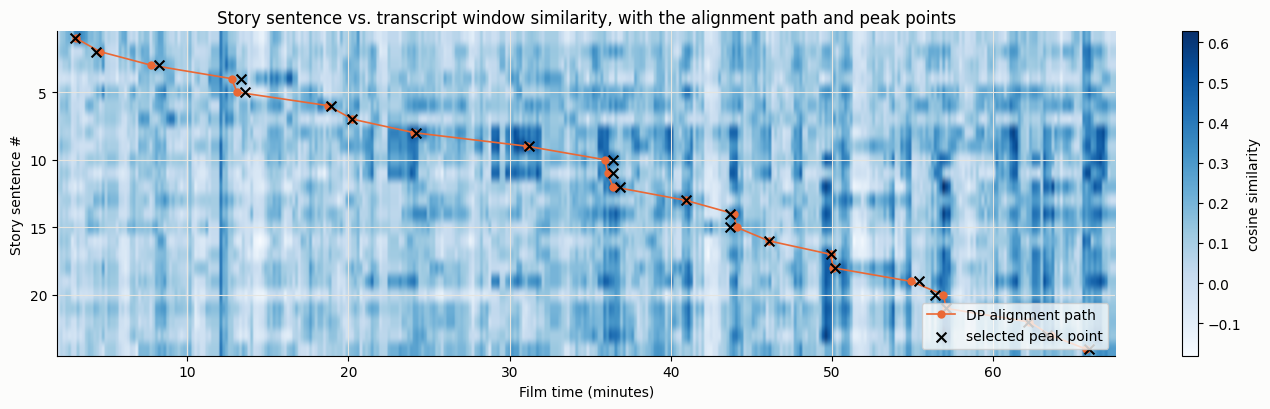

,#,time index,peak line (transcript),emotion,semantic,centrality,text_emotion,audio,visual,fused
0,1,00:03:02,"That music, it stinks!",disgust,1.0000,0.2875,0.9909,0.5626,0.3430,0.7276
1,2,00:04:19,"Sue, she was always selling it too.",disgust,0.6933,0.6086,0.7951,0.4232,0.4101,0.6129
2,3,00:08:13,"Al, look, I love you. You know I do.",joy,0.7697,0.6755,0.9286,0.5142,0.5112,0.7023
3,4,00:13:21,you'll click no don't try to stop me just expect me train who knows train plane,neutral,0.5805,0.6352,0.6320,0.4130,0.9685,0.6295
4,5,00:13:35,and then let's get married right away huh that's the stuff that's what I've been,neutral,0.3466,0.7141,0.1911,0.2458,0.5019,0.3866
5,6,00:18:54,a door. You get me in the arm here. Pretty mean cut.,disgust,0.6014,0.7193,0.9528,0.3718,0.2429,0.5836
6,7,00:20:12,"If I got him down on me, I'd buy a ticket to Hollywood.",neutral,0.8634,0.7833,0.4955,0.3146,0.4129,0.6463
7,8,00:24:13,fell out of the car why if Haskell came to which of course he couldn't even he,surprise,0.9461,0.6770,0.7549,0.5075,0.2750,0.7106
8,9,00:31:12,And then I found out from a letter Haskell was cutting around in his bag,surprise,0.9116,0.8900,0.9529,0.4904,0.2402,0.7507
9,10,00:36:23,He was sitting right there in the car laughing like mad while he haunted me.,fear,0.4753,0.7756,0.8754,0.5859,0.5771,0.6122


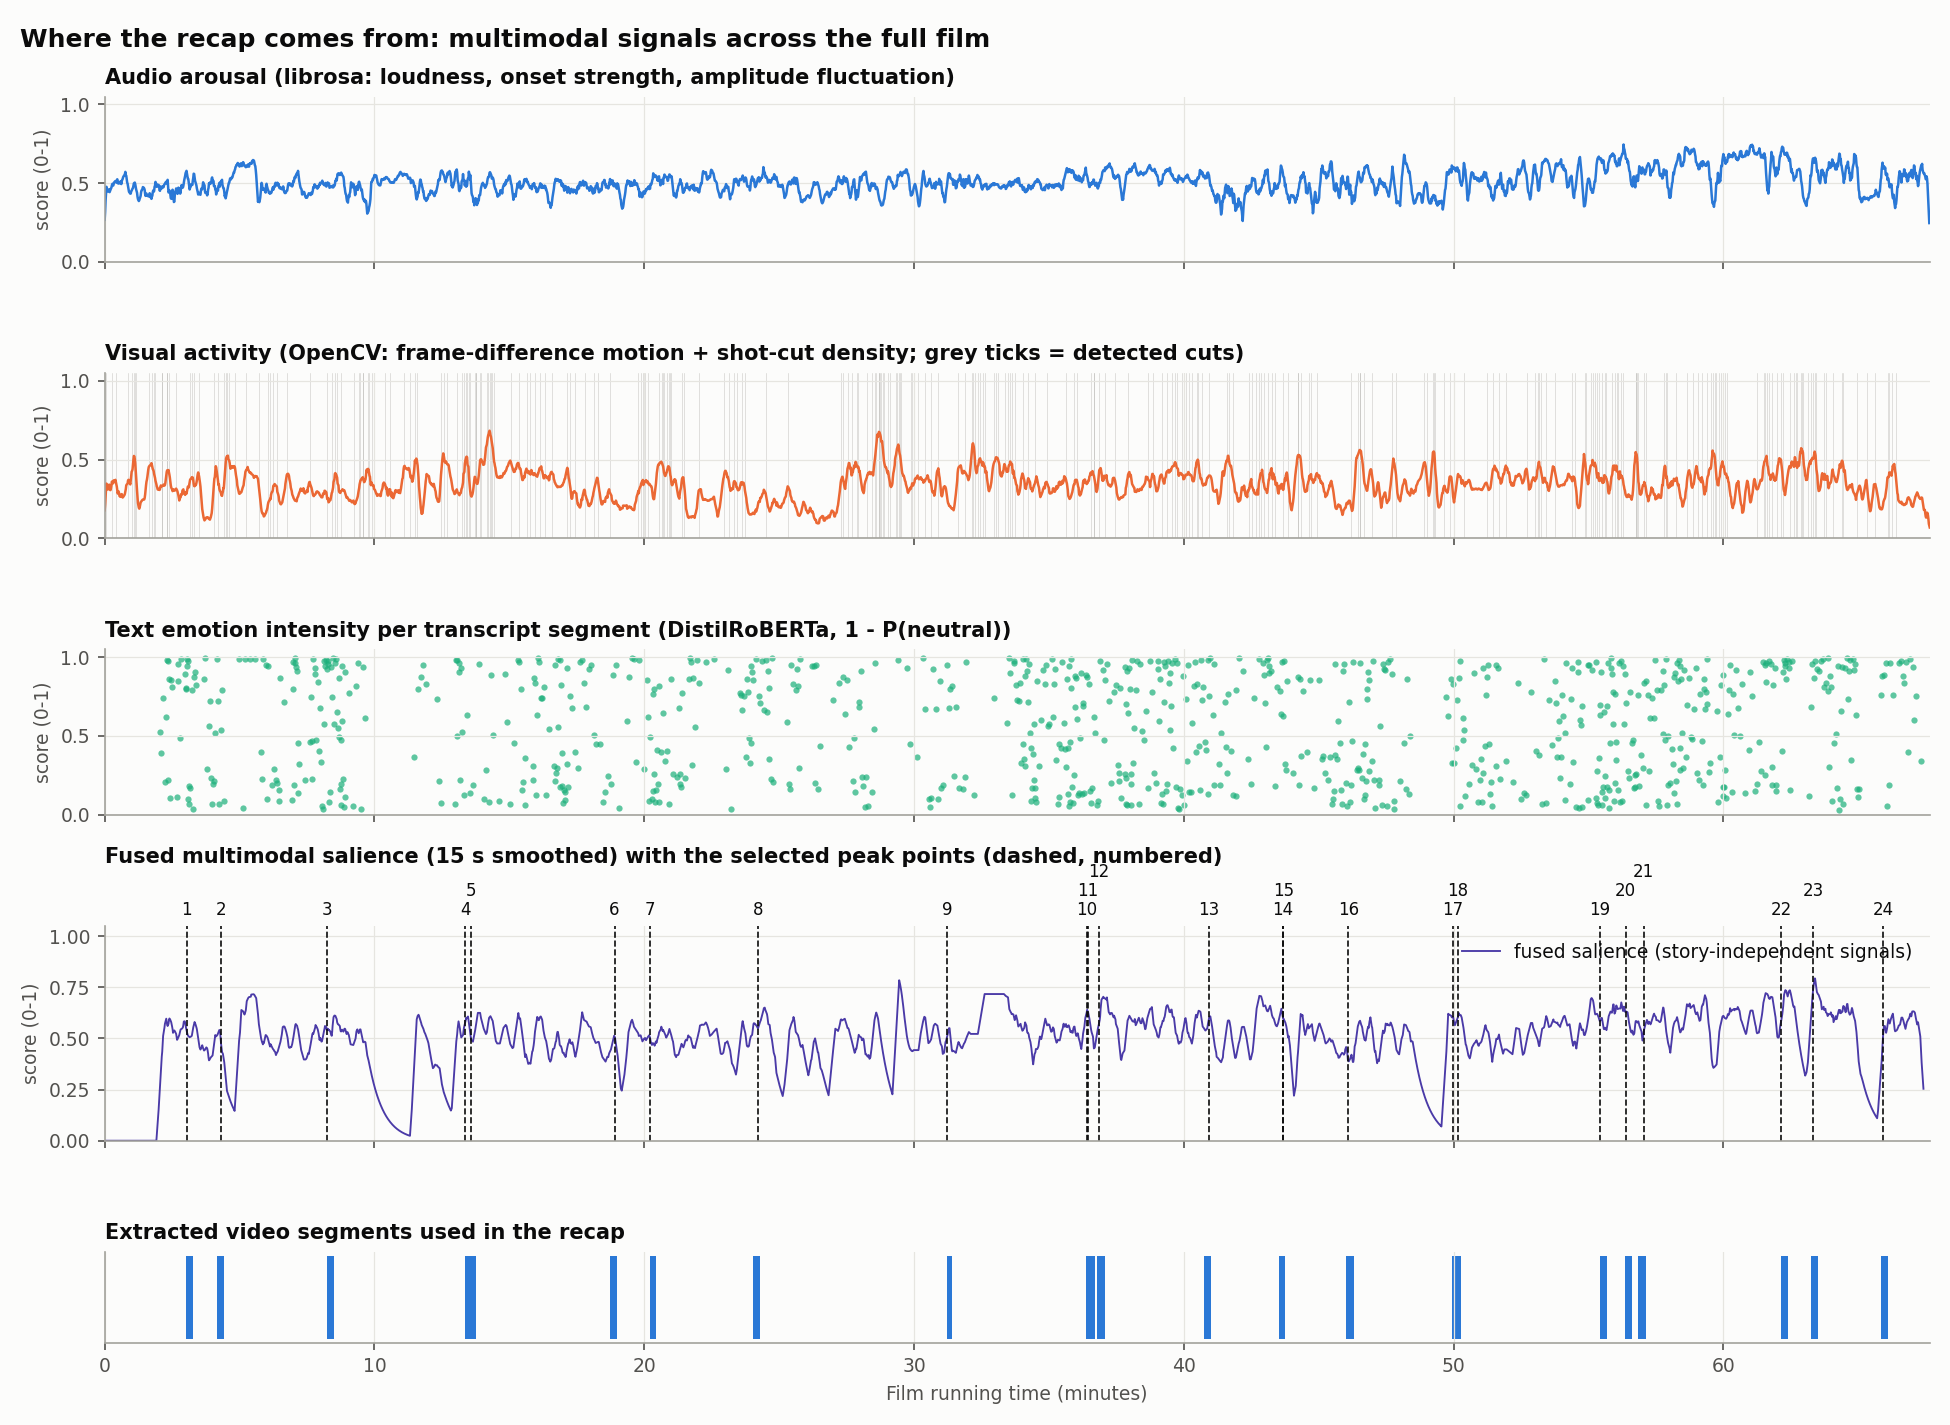

In [18]:
print("Greedy best window per sentence:", greedy, "(out of order)")
print("Monotonic DP alignment:        ", aligned, "(order preserved)")
plt.figure(figsize=(14, 4.2))
plt.imshow(sim, aspect="auto", cmap="Blues", extent=[centres[0], centres[-1], len(sim) + 0.5, 0.5])
plt.colorbar(label="cosine similarity")
plt.plot([centres[j] for j in pk["alignment_path"]], np.arange(1, len(sim) + 1), "o-", color=ORANGE, ms=5, lw=1.2,
         label="DP alignment path")
plt.scatter([p["timestamp"] / 60 for p in pk["peaks"]], np.arange(1, len(sim) + 1), marker="x", color="black",
            s=50, label="selected peak point", zorder=3)
plt.title("Story sentence vs. transcript window similarity, with the alignment path and peak points")
plt.xlabel("Film time (minutes)")
plt.ylabel("Story sentence #")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(pd.DataFrame([{"#": p["index"], "time index": p["timestamp_hms"], "peak line (transcript)": p["transcript"][:80],
                       "emotion": p["emotion_label"], **p["scores"]} for p in pk["peaks"]]))
display(Image(filename=str(OUT / "timeline.png"), width=1100))

**Reading the chart**

* **Observation:** The orange alignment path climbs steadily from the top-left to the bottom-right of the heatmap, and every selected peak (x) sits on or next to it. Fused peak scores range from 0.39 to 0.85, and the 24 peaks spread from 03:02 to 01:05:56.
* **Interpretation:** Story order and film order agree, so no sentence was matched to an unrelated scene that only shares a name. Pairs of sentences from the same chunk land a few seconds apart (for example peaks 10 and 11 at 36:23 and 36:26), because both describe the same scene.
* **Key insight:** The climax sentence lands exactly on the line "after killing Vera without really meaning to do it" (01:03:19), which shows the time index pointing at the right moment.

### Inference
The toy test confirms that the dynamic-programming alignment keeps story order where a greedy match does not. On the real film every story sentence receives one peak point with a precise Whisper timestamp, and the timeline shows the clips sitting on those peaks across the whole running time.

### Insights
Without the order constraint, a sentence about the ending could match an early scene that mentions "Haskell" or "the police". Tying each sentence to its own chunk keeps the recap balanced across the story arc. A limitation is that two sentences of one chunk can choose neighbouring peaks, which later produces two short clips of the same scene.

### Summary
Two levels of time index now exist for every sentence, the chunk span and the exact peak timestamp, both stored in `peaks.csv`. The next component cuts the film at these timestamps.

## 8. Video segment extraction (OpenCV) and the movie recap

### Objective
Cut the film at the peak timestamps and assemble a recap shorter than ten minutes.

### Purpose
This is the final product of the assignment: the summary, peak points and time indices become a watchable video.

### Methodology
`recap/segments.py` grows each peak line into a clip using the neighbouring dialogue that best matches its story sentence (up to about 32 s), pads it, snaps both ends to the nearest detected shot cut, and keeps clips chronological and non-overlapping within a 570-second budget. `recap/render.py` uses **OpenCV** to seek frame-accurately (`CAP_PROP_POS_FRAMES`), read and annotate every frame (original timecode, peak badge, white flash at the exact peak, film-position bar) and to draw chapter cards that narrate each story sentence with offline text-to-speech, loudness-matched to the film. Audio is assembled sample-locked to the number of written frames; ffmpeg only muxes and encodes. The narration engine reads fixed text and takes no instructions, so there is no prompt.

### Implementation
The first cell re-extracts the frame at each peak's time index with OpenCV. The second loads the edit decision list (EDL) and asserts the duration limit. The third grabs three frames from the finished recap.

In [19]:
# Re-extract the frame at every peak's time index with OpenCV
clips = load_json(OUT / "clips.json")
cap = cv2.VideoCapture(VIDEO)
peak_frames = []
for p in pk["peaks"]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(p["timestamp"] * info["fps"]))
    ok, frame = cap.read()
    peak_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
cap.release()

In [20]:
# Edit decision list and the hard duration check required by the assignment
edl = pd.read_csv(OUT / "recap_edl.csv")
recap_seconds = load_json(OUT / "render_info.json")["duration_seconds"]
assert recap_seconds < 600, "recap must be shorter than 10 minutes"
footage = edl[edl.type == "clip"].eval("recap_end - recap_start").sum()
cards = edl[edl.type != "clip"].eval("recap_end - recap_start").sum()

In [21]:
# Three frames from the finished recap: a chapter card, a clip, and the clip at its exact peak moment
cap = cv2.VideoCapture(str(OUT / "movie_recap.mp4"))
fps_r = cap.get(cv2.CAP_PROP_FPS)
row_card, row_clip = edl[edl.type == "chapter"].iloc[4], edl[edl.type == "clip"].iloc[4]
at_peak = row_clip.recap_start + (pk["peaks"][4]["timestamp"] - row_clip.source_start)
recap_frames = []
for t in (row_card.recap_start + 3, row_clip.recap_start + 1, at_peak + 0.1):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(t * fps_r))
    ok, frame = cap.read()
    recap_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
cap.release()

### Output
The results of the code above are displayed below.

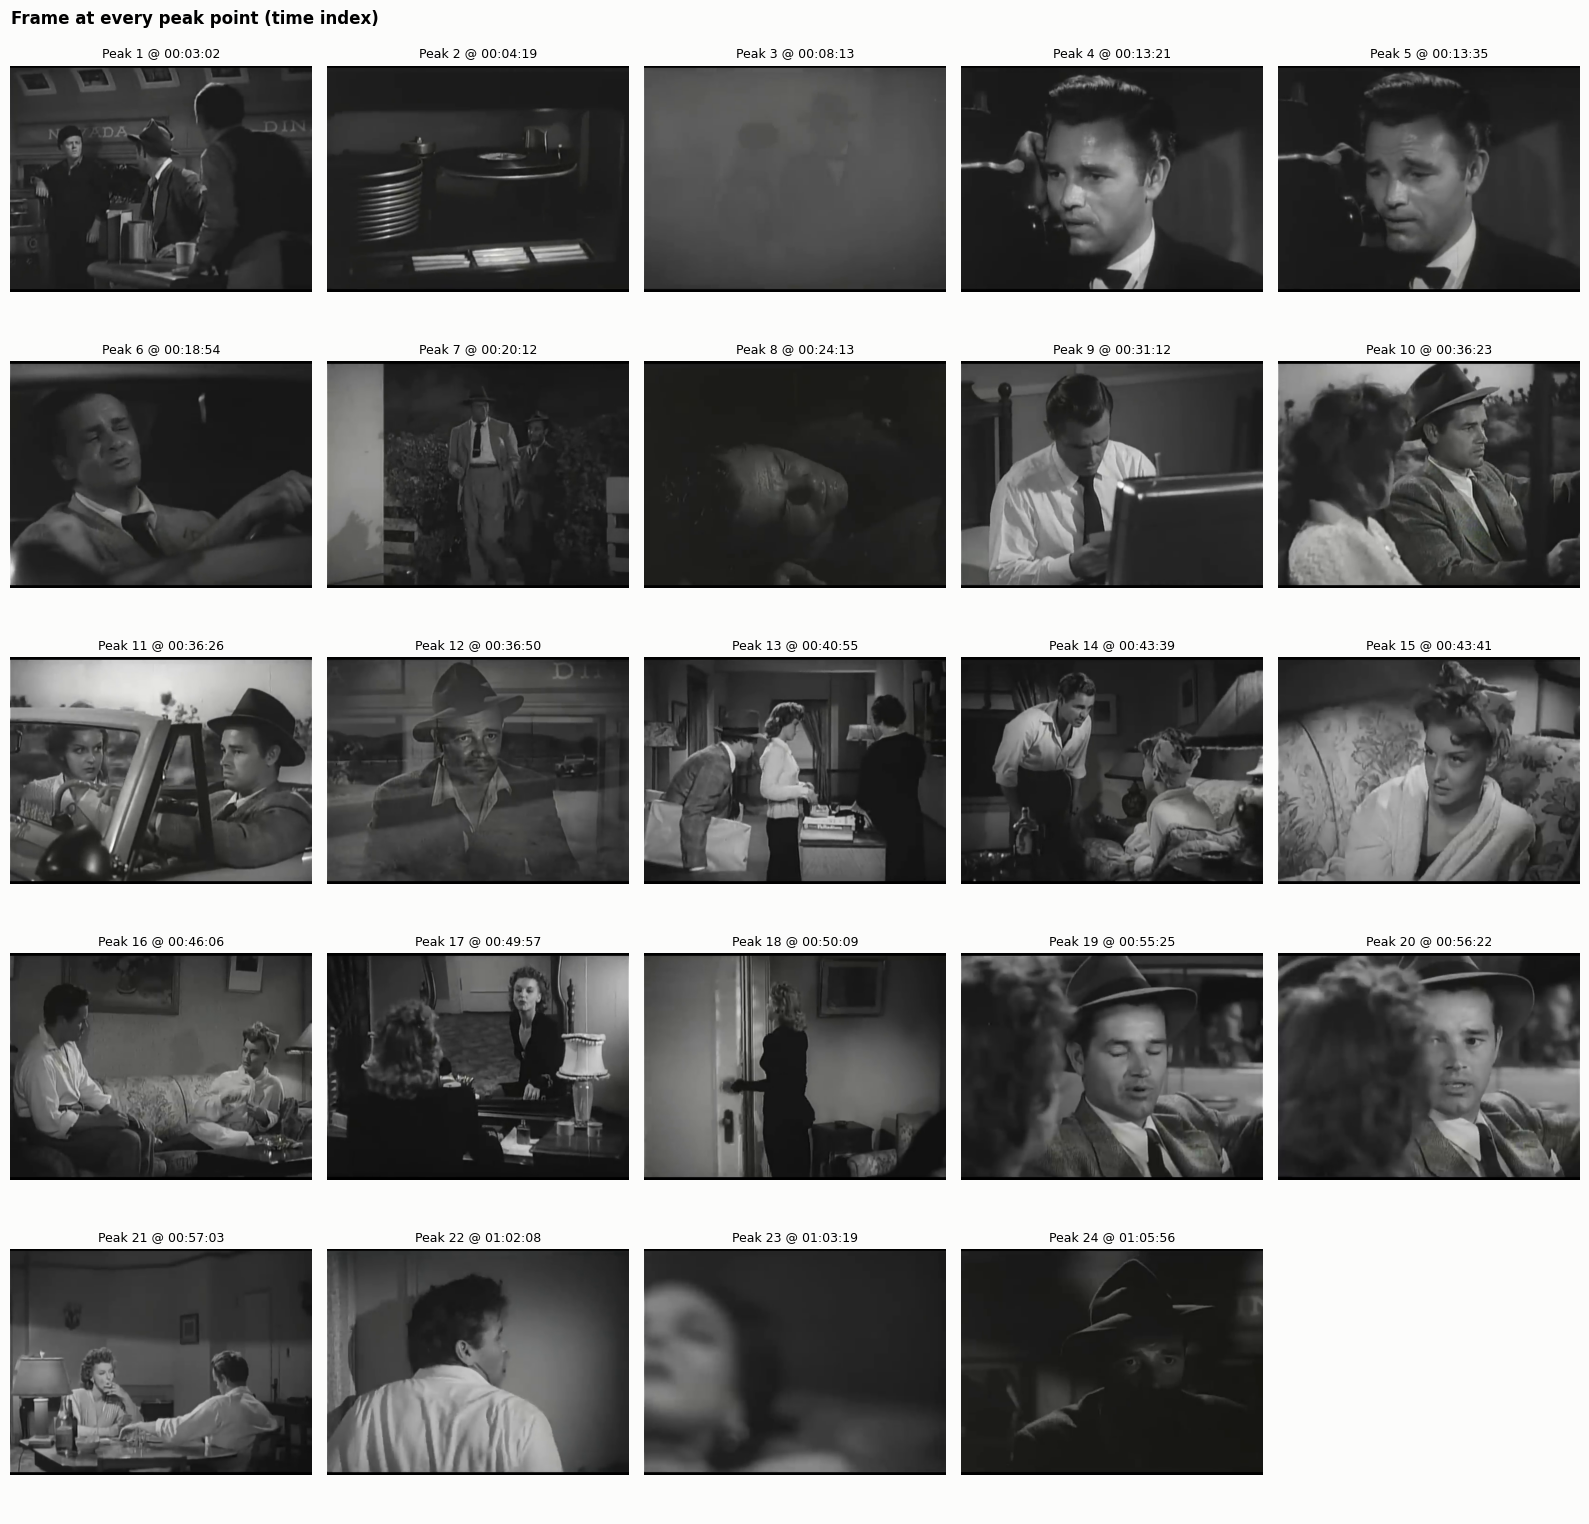

Recap: 00:08:44 (524.3 s) -> under 10 minutes: True
Footage 331 s, cards 193 s, compression 7.7x


,type,peak,recap_start,recap_end,source_start,source_end,text
0,intro,NaN,0.00,5.51,NaN,NaN,An AI-generated recap of Detour (1945).
1,chapter,1.0,5.51,11.81,NaN,NaN,"Al complains about the music at his club, causing a conflict with the"
2,clip,1.0,11.81,27.93,180.64,196.75,"Yeah, what's eating you? That music, it stinks! Oh, you don't like it,"
3,chapter,2.0,27.93,35.44,NaN,NaN,"Al reflects on his time at the old break at Dawn Club, missing his for"
4,clip,2.0,35.44,50.85,250.61,266.03,I used to love that song once. So did the customers back in the old br
5,chapter,3.0,50.85,57.16,NaN,NaN,"Al loses his appetite at the club, while Sue decides to leave for Holl"
6,clip,3.0,57.16,72.94,493.49,509.26,"Al, look, I love you. You know I do. And I want to marry you. But? But"
7,chapter,4.0,72.94,80.11,NaN,NaN,"Al continues his journey by thumbing rides, hoping to reach Los Angele"
8,clip,4.0,80.11,91.46,801.11,812.46,you'll click no don't try to stop me just expect me train who knows tr
9,chapter,5.0,91.46,96.76,NaN,NaN,"Al calls his girlfriend Sue, promising to see her soon."


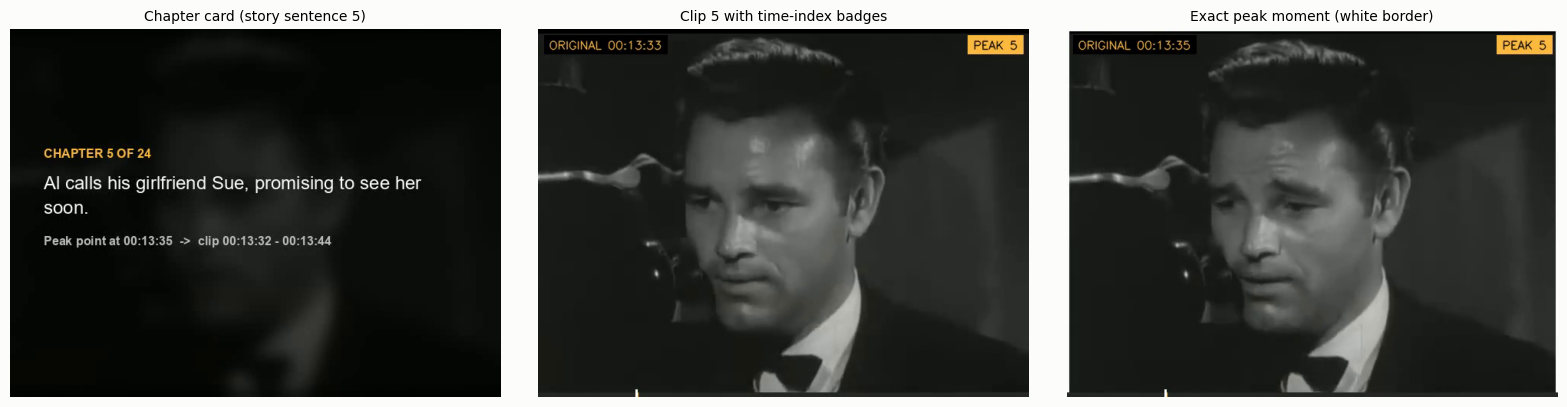

In [22]:
cols = 5
fig, axes = plt.subplots(int(np.ceil(len(peak_frames) / cols)), cols, figsize=(16, 3.1 * np.ceil(len(peak_frames) / cols)))
for ax in axes.flat:
    ax.axis("off")
for ax, p, frame in zip(axes.flat, pk["peaks"], peak_frames):
    ax.imshow(frame)
    ax.set_title(f"Peak {p['index']} @ {p['timestamp_hms']}", fontsize=9)
fig.suptitle("Frame at every peak point (time index)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Recap: {fmt_ts(recap_seconds)} ({recap_seconds:.1f} s) -> under 10 minutes: {recap_seconds < 600}")
print(f"Footage {footage:.0f} s, cards {cards:.0f} s, compression {info['duration_seconds'] / recap_seconds:.1f}x")
display(edl.assign(text=edl.text.str.slice(0, 70)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, frame, title in zip(axes, recap_frames, ["Chapter card (story sentence 5)", "Clip 5 with time-index badges",
                                                 "Exact peak moment (white border)"]):
    ax.imshow(frame)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Reading the chart**

* **Observation:** The peak frames show the right characters at the right points (the club, the road, the car, the apartment), and the three recap frames show a chapter card, a clip with its original-time badge, and the white border that marks the exact peak moment.
* **Interpretation:** Every clip carries its own provenance on screen: original timecode, peak number and position bar, so a viewer can check each claim of the story against the film.
* **Key insight:** The relationship between summary, peak point, time index and segment, which the assignment asks to demonstrate, is visible in the video itself, not only in the code.

### Inference
The recap runs **8 min 44 s** (524 s), under the 10-minute limit, with 5.5 minutes of original footage and narrated chapter cards for the 24 story sentences; it compresses the 67-minute film 7.7 times. The duration assertion passes.

### Insights
Snapping cuts to shot boundaries avoids starting a clip on a stray frame of the previous shot. More story sentences mean shorter clips: with 24 chapters the average clip is about 14 s (run E: 13 chapters, about 30 s), a trade-off between story completeness and how much of each scene is shown. The limit is enforced in code (planning budget plus an assertion after rendering), not left to chance.

### Summary
The movie recap is complete; the next component measures how good the summary is and whether the recap contains the intended content.

## 9. Evaluation: BLEU, recap fidelity and ablation

### Objective
Quantify the quality of the summary story and verify that the recap contains the intended scenes.

### Purpose
Without measurement the pipeline's claims cannot be trusted; the assignment specifically asks for a BLEU comparison.

### Methodology
* **BLEU** (Papineni et al., 2002): $\text{BLEU} = BP \cdot \exp\big(\sum_{n=1}^{4} \tfrac14 \log p_n\big)$, with clipped n-gram precision $p_n$ and brevity penalty $BP = \min(1, e^{1 - r/c})$; implemented from first principles in `recap/bleu.py` and cross-checked against NLTK and sacreBLEU. ROUGE-1/2/L and embedding similarity are reported alongside.
* **Reference:** the human-written Wikipedia plot (526 words). Four baselines of equal length: extractive TextRank, the first N words, uniformly spaced lines and random lines.
* **Recap fidelity:** each clip is cut from the *finished recap* and transcribed again; its BLEU against the original transcript at the mapped timestamps tests the whole chain. The session suggested about 0.7 as a "good enough" BLEU.
* **Ablation:** peaks chosen with text-only weights are compared with the multimodal fusion.

The evaluation is algorithmic, so there is no prompt.

### Implementation
The first cell runs a worked BLEU example through the three implementations. The second loads the stored evaluation (`evaluation.json`) produced by `recap/evaluate.py`.

In [23]:
# Worked BLEU example: own implementation vs NLTK vs sacreBLEU on one sentence pair
from recap.bleu import bleu, tokenize
from nltk.translate.bleu_score import SmoothingFunction, corpus_bleu

cand = "Al picks up Vera, a hitchhiker, who threatens to turn him over to the police."
ref = "Al crosses into California and picks up a hitchhiker named Vera. She blackmails Al by threatening to turn him over to the police."
own = bleu(cand, [ref])
nltk_score = corpus_bleu([[tokenize(ref)]], [tokenize(cand)], smoothing_function=SmoothingFunction().method2)
sacre_score = sacrebleu.sentence_bleu(cand, [ref]).score / 100

In [24]:
# Stored evaluation results from the pipeline run
ev = load_json(OUT / "evaluation.json")
fid, ab = ev["recap_fidelity"], ev["ablation"]
metric_cols = ["bleu4", "bleu4_nltk", "sacrebleu", "bleu1", "rouge1", "rouge2", "rougeL", "semantic_similarity", "plot_coverage@0.5", "words"]

### Output
Worked example, summary versus reference with baselines, recap fidelity and the ablation:

n-gram precisions: [0.778, 0.556, 0.412, 0.375] | brevity penalty: 0.678
BLEU own = 0.3445 | NLTK = 0.3445 | sacreBLEU = 0.3228


,bleu4,bleu4_nltk,sacrebleu,bleu1,rouge1,rouge2,rougeL,semantic_similarity,plot_coverage@0.5,words
Summary story (ours),0.0403,0.0403,0.0353,0.4066,0.4143,0.0913,0.1909,0.8097,0.56,410
Extractive TextRank,0.0205,0.0205,0.0156,0.3241,0.3187,0.0507,0.1341,0.4523,0.16,411
Lead-N (first words),0.0158,0.0158,0.0096,0.2853,0.2472,0.0156,0.1069,0.3053,0.0,410
Uniform segments,0.0141,0.0141,0.0067,0.2712,0.2805,0.0317,0.1244,0.4652,0.08,376
Random segments,0.0149,0.0149,0.01,0.2936,0.2989,0.0242,0.1187,0.3771,0.12,410


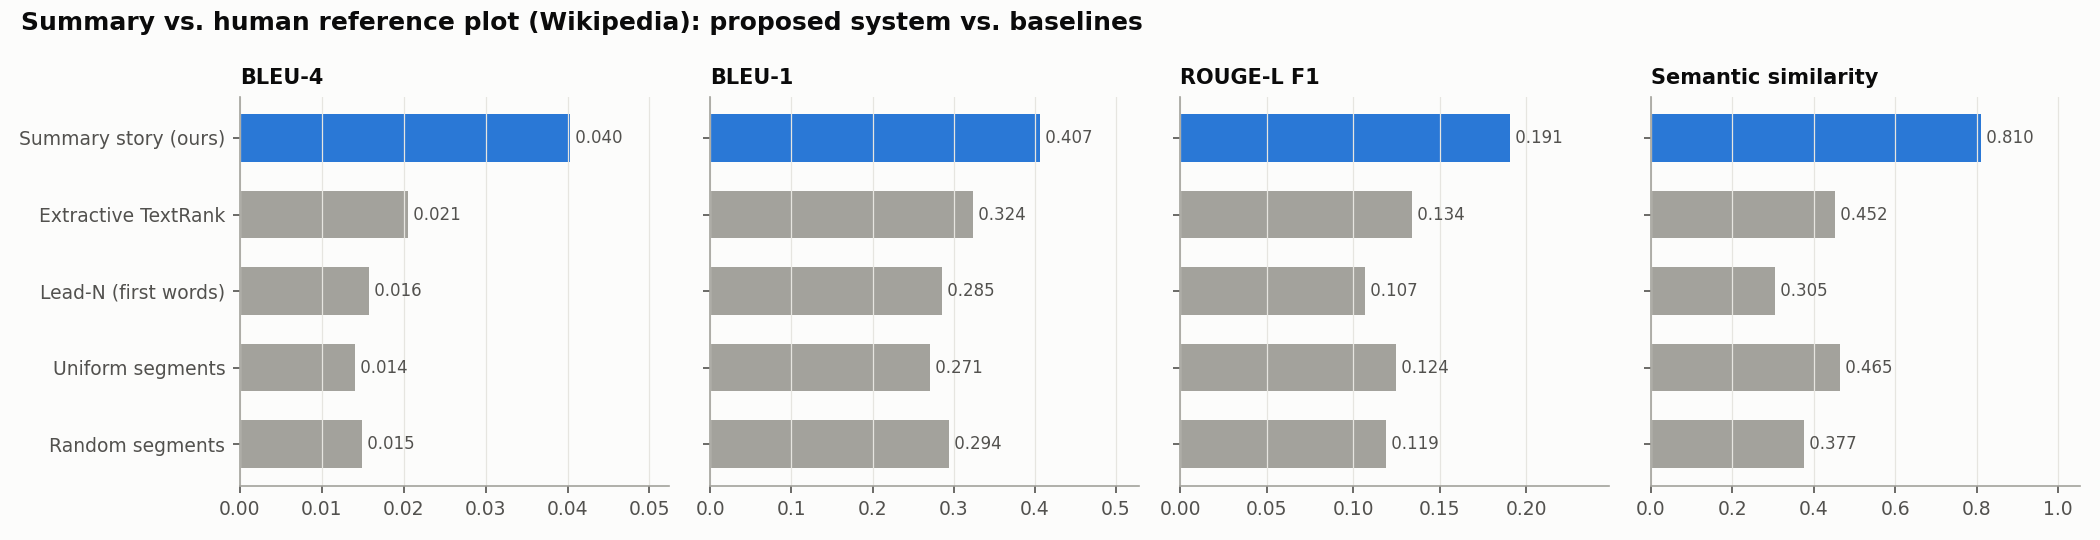

,mean_clip_bleu,median_clip_bleu,peak_hit_rate@0.6,overall_bleu,mean_narration_bleu
0,0.7307,0.7668,0.9167,0.8096,0.9665


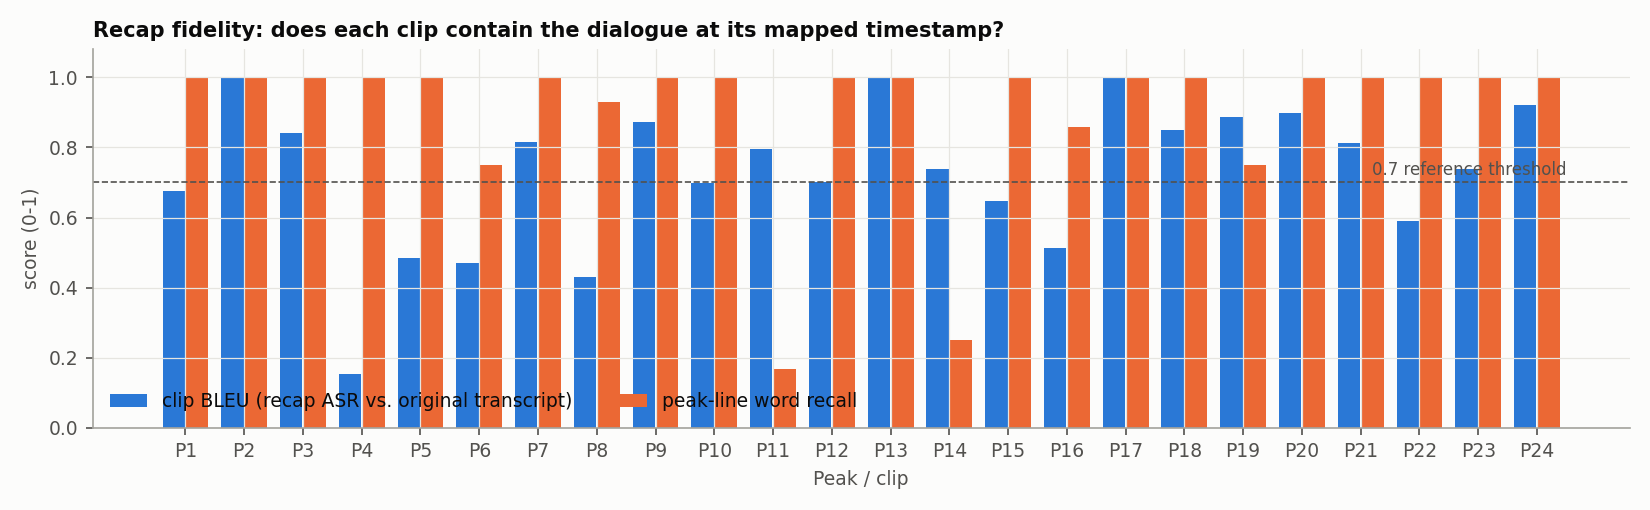

,semantic,centrality,text_emotion,audio,visual
text only (semantic + centrality),0.8655,0.6252,0.5006,0.5697,0.3825
multimodal fusion (proposed),0.7504,0.6557,0.7731,0.5544,0.4972


Peaks moved by adding audio, visual and emotion signals: 13 of 24 (mean shift 12.4 s)


In [25]:
print("n-gram precisions:", [round(p, 3) for p in own["precisions"]], "| brevity penalty:", round(own["bp"], 3))
print(f"BLEU own = {own['bleu']:.4f} | NLTK = {nltk_score:.4f} | sacreBLEU = {sacre_score:.4f}")
display(pd.DataFrame(ev["summary_vs_reference"]).T[metric_cols])
display(Image(filename=str(OUT / "metrics.png"), width=1100))
display(pd.DataFrame([{k: fid[k] for k in ("mean_clip_bleu", "median_clip_bleu", "peak_hit_rate@0.6", "overall_bleu", "mean_narration_bleu")}]))
display(Image(filename=str(OUT / "fidelity.png"), width=950))
display(pd.DataFrame({"text only (semantic + centrality)": ab["text_only_profile"],
                      "multimodal fusion (proposed)": ab["multimodal_profile"]}).T)
print(f"Peaks moved by adding audio, visual and emotion signals: {ab['peaks_changed']} of {len(pk['peaks'])} "
      f"(mean shift {ab['mean_shift_seconds']} s)")

**Reading the chart**

* **Observation:** In `metrics.png` the summary story has the tallest bar for every metric. In `fidelity.png` most clips score between 0.6 and 1.0, with a few low outliers (the lowest is clip 4 at 0.15).
* **Interpretation:** The baselines are close to each other and far below the story, so the gap comes from the summariser, not from length or chance. Low-fidelity clips are short scenes where music or overlapping speech changes what Whisper hears the second time.
* **Key insight:** Both the summary (against the human plot) and the recap (against the original film) are measured, so quality is checked at both ends of the pipeline.

### Inference
* The hand-written BLEU matches NLTK exactly (0.0403); sacreBLEU (0.0353) differs slightly because of its own tokenizer.
* The summary story beats all four baselines on every metric: BLEU-4 0.040 vs at most 0.021, BLEU-1 0.41 vs 0.32, ROUGE-L 0.19 vs 0.13, semantic similarity 0.81 vs 0.47, and plot coverage 0.56 vs 0.16.
* Recap fidelity: mean clip BLEU 0.73 (median 0.77), above the 0.7 threshold suggested in class; 92 % of peak lines are heard in their clip, and the narration is recognised almost perfectly (0.97).
* Fusion moves 13 of 24 peaks (mean shift 12 s) and raises the emotion intensity of the chosen lines from 0.50 to 0.77, at a cost in semantic match (0.87 to 0.75).

### Insights
Absolute BLEU is low for every system because BLEU counts exact word sequences and an independent human plot rarely shares phrasing. Writing two sentences per chunk raised the brevity penalty from 0.50 (run E) to 0.76 and BLEU-4 from 0.030 to 0.040. Semantic similarity fell slightly (0.86 to 0.81) because the longer story includes more scene detail that the short reference does not mention. Fidelity is a little lower than run E (0.80) because 24 shorter clips leave less context around each peak line.

### Summary
The evaluation confirms both the quality of the story and the correctness of the time-index chain; the next section compares the summariser versions behind these numbers.

## 10. Model comparison (summarisation stage)

### Objective
Compare the candidate summarisers and justify the one used for the submission.

### Purpose
The summariser has the largest influence on recap quality, so its choice must be backed by evidence.

### Methodology
All variants run on the same transcript and are scored against the same reference. No model is trained (all are pre-trained and used zero-shot), so training time is not applicable; testing time is the measured CPU time to summarise the whole film. TextRank is timed live; LLM times come from the pipeline logs. The LLM variants use the same prompt shown in Section 6, so no new prompt is introduced here.

### Implementation
The cell times the TextRank baseline live, loads the stored scores of the 3B run, and assembles the comparison table.

In [26]:
# Time the extractive baseline live; LLM figures come from the logged pipeline runs
from recap.summarize import textrank_scores, extractive_summary

t0 = time.time()
cent = textrank_scores(segs, model)
_ = extractive_summary(segs, cent, target_words=len(summ["story"].split()))
textrank_seconds = time.time() - t0

ev3 = load_json(OUT.parent / "experiments" / "evaluation_qwen2.5-3b_grounded.json")["summary_vs_reference"]["Summary story (ours)"]
ev_e = load_json(OUT.parent / "experiments" / "evaluation_qwen2.5-7b_runE.json")["summary_vs_reference"]["Summary story (ours)"]
base = ev["summary_vs_reference"]
v2_minutes = load_json(OUT.parent / "experiments" / "timings_v2.json")["v2_full_llm_summary_minutes"]
ev_c = load_json(OUT.parent / "experiments" / "evaluation_qwen2.5-7b_v2c.json")["summary_vs_reference"]["Summary story (ours)"]
rows = [
    ["Qwen2.5-7B, notes + editor + key-event and entry checks (v2, proposed)", base["Summary story (ours)"], "none (pre-trained)",
     f"{v2_minutes:.1f} min", "Grounded in quoted evidence; role errors and repeats corrected; climax and ending kept",
     "Slowest variant (extra editor and repair calls)", "Offline recap generation where factual accuracy matters"],
    ["Qwen2.5-7B, v2c (same notes, earlier key-event prompt)", ev_c, "none (pre-trained)", f"{v2_minutes:.1f} min",
     "Highest plot coverage (0.64)", "Added sentences in first person and partly invented ('in a fit of rage')",
     "Not submitted: factual errors outweigh the coverage gain"],
    ["Qwen2.5-7B, rolling context (run E)", ev_e, "none (pre-trained)", "30.6 min",
     "Coherent arc, good semantic similarity", "Role errors (Vera named before she enters the film), repeated events, climax and ending missing",
     "Quick drafts when an editor pass is too slow"],
    ["Qwen2.5-3B, rolling context (run D)", ev3, "none (pre-trained)", "~14.5 min",
     "2x faster; higher BLEU-1 because it writes more words", "Repeats context sentences; invents events", "Low-RAM machines"],
    ["Extractive TextRank", base["Extractive TextRank"], "none", f"{textrank_seconds:.0f} s",
     "No hallucination; legally safest (original lines only)", "Dialogue lines do not tell a story", "Fallback when no LLM is available"],
    ["Uniform segments", base["Uniform segments"], "none", "< 1 s", "Trivial, unbiased coverage", "Ignores content", "Baseline only"],
    ["Random segments", base["Random segments"], "none", "< 1 s", "Trivial", "Ignores content and order", "Baseline only"],
]
comparison = pd.DataFrame([{"Model": r[0], "Performance (BLEU-4 / ROUGE-L / semantic / plot coverage)": f"{r[1]['bleu4']:.3f} / {r[1]['rougeL']:.3f} / {r[1]['semantic_similarity']:.3f} / {r[1]['plot_coverage@0.5']:.2f}",
                            "Training time": r[2], "Testing time": r[3], "Strengths": r[4], "Limitations": r[5],
                            "Suitable use cases": r[6]} for r in rows])

### Output
The results of the code above are displayed below.

In [27]:
comparison

,Model,Performance (BLEU-4 / ROUGE-L / semantic / plot coverage),Training time,Testing time,Strengths,Limitations,Suitable use cases
0,"Qwen2.5-7B, notes + editor + key-event and entry checks (v2, proposed)",0.040 / 0.191 / 0.810 / 0.56,none (pre-trained),32.8 min,Grounded in quoted evidence; role errors and repeats corrected; climax and ending kept,Slowest variant (extra editor and repair calls),Offline recap generation where factual accuracy matters
1,"Qwen2.5-7B, v2c (same notes, earlier key-event prompt)",0.041 / 0.192 / 0.838 / 0.64,none (pre-trained),32.8 min,Highest plot coverage (0.64),Added sentences in first person and partly invented ('in a fit of rage'),Not submitted: factual errors outweigh the coverage gain
2,"Qwen2.5-7B, rolling context (run E)",0.030 / 0.181 / 0.856 / 0.56,none (pre-trained),30.6 min,"Coherent arc, good semantic similarity","Role errors (Vera named before she enters the film), repeated events, climax and ending missing",Quick drafts when an editor pass is too slow
3,"Qwen2.5-3B, rolling context (run D)",0.040 / 0.191 / 0.812 / 0.72,none (pre-trained),~14.5 min,2x faster; higher BLEU-1 because it writes more words,Repeats context sentences; invents events,Low-RAM machines
4,Extractive TextRank,0.021 / 0.134 / 0.452 / 0.16,none,5 s,No hallucination; legally safest (original lines only),Dialogue lines do not tell a story,Fallback when no LLM is available
5,Uniform segments,0.014 / 0.124 / 0.465 / 0.08,none,< 1 s,"Trivial, unbiased coverage",Ignores content,Baseline only
6,Random segments,0.015 / 0.119 / 0.377 / 0.12,none,< 1 s,Trivial,Ignores content and order,Baseline only


### Inference
The proposed v2 summariser has the best BLEU-4 (0.040), BLEU-1 and ROUGE-L of all variants and every baseline, and it is the only one whose story contains the correct climax. Run E keeps a slightly higher semantic similarity (0.86 vs 0.81) with a shorter story, and v2c reaches the highest plot coverage (0.64) but with invented details.

### Insights
No single metric picks the right model: BLEU rewards length and wording, semantic similarity rewards brevity, plot coverage rewards mentioning many events even with wrong details. The choice therefore weighs metrics together with factual checks of the story against the film. The 7B LLM costs about 33 minutes of CPU time for the summary, roughly twice the 3B model; TextRank stays the automatic fallback because it needs no LLM and cannot hallucinate.

### Summary
**Recommended model: Qwen2.5-7B-Instruct with grounded notes, editor pass, key-event check and character-entry check (v2)**, used for the submitted recap.

## 11. Conclusion

**Overall findings.** The pipeline turns a 67-minute YouTube film into an **8 min 44 s** recap (7.7× shorter, under the
10-minute limit) on a CPU with open models only. The summary story beats all four baselines on BLEU-4 (0.040), BLEU-1,
ROUGE and semantic similarity, the recap passes an end-to-end fidelity check (mean clip BLEU 0.73, 92 % of peak lines
heard), and 27 automated tests pass.

**Best-performing configuration.** Whisper small.en → Qwen2.5-7B with grounded notes, an editor pass and two deterministic
checks (key events, character entry) → monotonic DP alignment → five-signal post-fusion for peaks → OpenCV rendering with
shot-snapped cuts.

**Why it works.** Each stage carries the time index forward explicitly (chunk span → aligned window → peak line → clip →
recap position), so every sentence of the summary can be traced to a moment in the film, and the checks that matter most
(is a key event missing, is a character named too early) are rules on the transcript rather than model guesses.

**Error analysis of the final story (honest limitations).**

| Sentence | What the story says | What the film shows | Cause |
|---|---|---|---|
| 6 | Al throws a hitchhiker out of his car | Haskell tells Al about a hitchhiker who scratched him | Narrated anecdote taken as a current event |
| 10 | Al realises Vera is Haskell | Al realises Vera knew Haskell | Pronoun and role confusion |
| 12, 14 | Al suspects Vera of the killing | Vera accuses Al of killing Haskell | No speaker labels in the transcript |

The two deterministic checks removed the earlier errors of the same kind that they can detect (a name before its first
mention, a missing death); the remaining ones need speaker identity, which the transcript does not provide.

**Practical applications.** Film and series recaps, "previously on" segments for lectures, highlight reels of meetings and
interviews, and browsing public-domain archives.

**Future improvements.** Speaker diarisation (e.g. pyannote) so the model knows who speaks each line, which addresses all
remaining role errors; a vision-language model (CLIP) to match story sentences to frames; merging same-scene peaks into one
longer clip; a larger or fine-tuned LLM; a FastAPI service around the stages, as recommended in the Day 4 session.

## 12. References

1. A. Radford et al., "Robust Speech Recognition via Large-Scale Weak Supervision" (Whisper), 2022; SYSTRAN faster-whisper / CTranslate2.
2. K. Papineni et al., "BLEU: a Method for Automatic Evaluation of Machine Translation", ACL 2002.
3. C.-Y. Lin, "ROUGE: A Package for Automatic Evaluation of Summaries", 2004; C.-Y. Lin and F. J. Och, "ORANGE", COLING 2004 (BLEU smoothing).
4. R. Mihalcea and P. Tarau, "TextRank: Bringing Order into Texts", EMNLP 2004.
5. N. Reimers and I. Gurevych, "Sentence-BERT", EMNLP 2019 (`all-MiniLM-L6-v2`).
6. J. Hartmann, "Emotion English DistilRoBERTa-base", Hugging Face, 2022.
7. Qwen Team, "Qwen2.5 Technical Report", 2024; Ollama.
8. B. McFee et al., "librosa: Audio and Music Signal Analysis in Python", SciPy 2015; OpenCV; yt-dlp; NLTK; M. Post, "A Call for Clarity in Reporting BLEU Scores" (sacreBLEU), 2018.
9. Wikipedia, "Detour (1945 film)", Plot section (CC BY-SA 4.0), used as the reference summary.
10. *Detour* (1945), Producers Releasing Corporation, public domain; YouTube upload https://www.youtube.com/watch?v=tap67KjjPu8.
11. AI11 Module 8 Day 4 class notes, Dr. J. B. Simha (multimodal fusion, BLEU threshold, movie summarisation assignment).